---
---
# CONFIDENCE INTERVALS

---
---

## ROADMAP: where we've been, and where we're going

* When we analyze data, the data is most often based on a **sample** $\mathcal{S}$ taken from a broader **population** $\mathcal{P}$. We think of the sample as a *proxy* for the population.

* Usually interest lies in calculating an **attribute** of the population $a(\mathcal{P})$. 

* But because we don't have access to the population, we instead calculate the attribute in the sample: $a(\mathcal{S})$. We think of the sample attribute $a(\mathcal{S})$ as an **estimate** of the population attribute $a(\mathcal{P})$.

* This is the core of **statistical inference**: we use sample data to draw conclusions about the broader population.

* As we've seen, the quality of inference depends on the quality of the sample. Different samples may yield very different **estimates** of population attributes. This was demonstrated via **sampling distributions**.

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/repeated_samples.svg" alt="repeated_resamples" width="300"/>
</div>

* So, when we calculate a sample estimate we need to acknowledge that *it's specific to our sample*, and if we'd had a different sample, we'd have obtained a different estimate. This kind of **sampling variability** needs to be acknowledged and ideally quantified.

* We do this with a **confidence interval**, an interval of numbers that we believe contains the true population attribute. Confidence intervals are reported alongside sample estimates to communicate our uncertainty in the estimate and to provide a broader sense of what the population attribute value might be. 


---
---

## Revisiting Sampling Distributions

Recall the Titanic data which recorded several variables for each of the 2207 passengers and crew members on board the infamous ocean liner the night it sank. Sadly, only 711 (32.2%) of those passengers and crew members survived.

Previously we were interested in *estimating* this survival rate using samples from the full population. Below we take $N=10,000$ samples of $n=100$ passengers/crew from the Titanic and calculate the survival rate in each of those samples. The histogram visualizes all of those estimates. It visualizes the sampling distribution of the survival rate.

In [24]:
# Load necessary libraries
import pandas as pd
import numpy as np
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [15]:
# Read in the data
titanic = pd.read_csv("https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/data/titanic_passenger_info.csv")

In [45]:
# Take 10,000 samples of size n=100 and calculate the survival rate in each
N = 10000
sample_surv_rates = []
for i in range(N):
    sample = titanic.sample(n=100)
    surv_rate = sample["survived"].value_counts(normalize = True).get("yes", 0)
    sample_surv_rates.append(surv_rate)

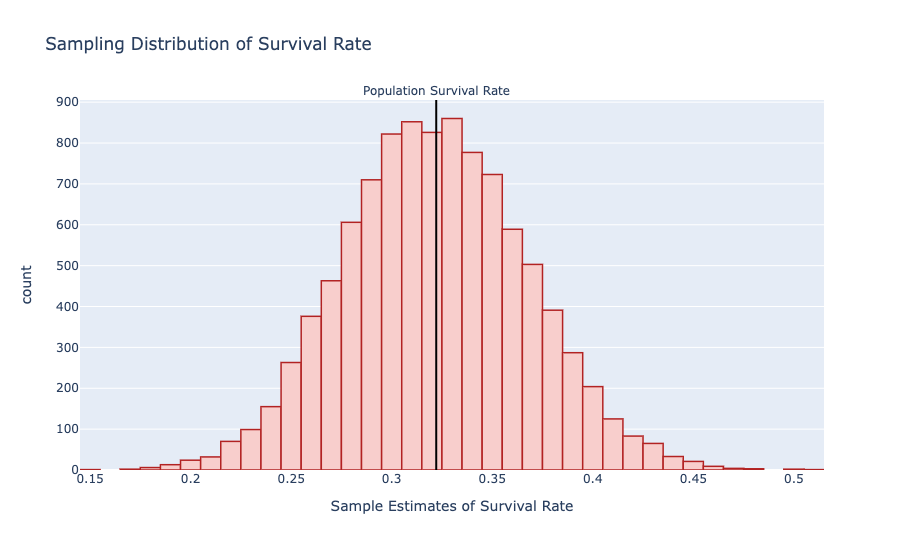

In [195]:
# Visualize the 10,000 sample estimates
sample_surv_rates = pd.Series(sample_surv_rates)
fig = px.histogram(sample_surv_rates,
                   title = "Sampling Distribution of Survival Rate",
                   labels = {"value":"Sample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC", 
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

pop_surv_rate = titanic["survived"].value_counts(normalize = True).loc["yes"]
fig.add_vline(x = pop_surv_rate,
              line_width=2,            
              line_dash="solid",       
              line_color="black",         
              annotation_text="Population Survival Rate",      
              annotation_position="top")

### Interpreting the sampling distribution

**What does this sampling distribution tell us?** 

Previously we drew the following conclusion:
> The "bump" of the histogram is concentrated around the true, population survival rate. This tells us that if you take a sample at random, it's quite likely that you'll get one whose survival rate estimate is close to the population value.

But having now discussed **probability**, we can formalize this insight:
* What's the probability that the survival rate of a randomly selected sample of size $n=100$ lies within $\pm$0.05 of the true population survival rate? 
    * In other words, what's the probability that a randomly selected sample's survival rate lies in the interval 0.32$\pm$0.05 = (0.32-0.05, 0.32+0.05) = (0.27, 0.37)?
    * This is a question of **relative frequency**: among the $N=10,000$ random samples, what proportion of them had survival rates within (0.27, 0.37)?

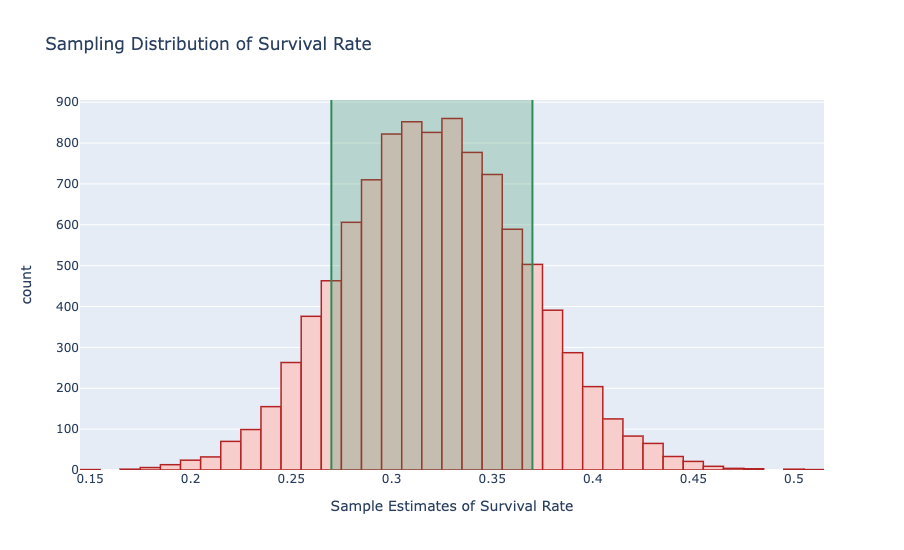

In [111]:
results = pd.DataFrame({"surv rates":sample_surv_rates})
results["event"] = (results["surv rates"] >= 0.27) & (results["surv rates"] <= 0.37)

fig = px.histogram(results, x = "surv rates", color = "event",
                   title = "Sampling Distribution of Survival Rate",
                   labels = {"surv rates":"Sample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC", 
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

fig.add_vline(x = 0.27, line_width=2, line_dash="solid", line_color="seagreen")
fig.add_vline(x = 0.37, line_width=2, line_dash="solid", line_color="seagreen")
fig.add_vrect(x0 = 0.27, x1 = 0.37, fillcolor = "seagreen", opacity = 0.25, line_width = 0)

We answer this question in stages:

1. Translate the event of interest into a logical statement: `(sample_surv_rates >= 0.27) & (sample_surv_rates <= 0.37)`
2. Count how many elements of the resulting boolean series are `True`.
3. The relative frequency is the count from step 2 divided by `N`.

**Note:** we could combine steps 2 and 3 by simply taking the mean of the boolean series.

In [196]:
event = (sample_surv_rates >= 0.27) & (sample_surv_rates <= 0.37)
count = event.sum()
relative_frequency = count / N
print(f"The probability of interest is estimated to be {relative_frequency}")

The probability of interest is estimated to be 0.7731


---

### ACTIVITY 💻: What is the probability a randomly selected sample's survival rate is more than 0.1 from the true population survival rate?

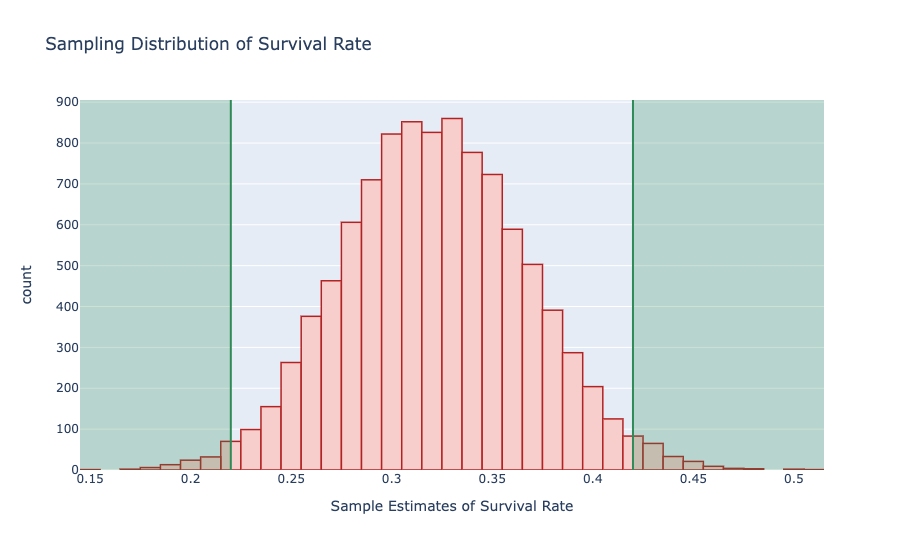

In [113]:
results = pd.DataFrame({"surv rates":sample_surv_rates})
results["event"] = (results["surv rates"] < 0.22) | (results["surv rates"] > 0.42)

fig = px.histogram(results, x = "surv rates", color = "event",
                   title = "Sampling Distribution of Survival Rate",
                   labels = {"surv rates":"Sample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC",
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

fig.add_vrect(x0 = 0.145, x1 = 0.22, fillcolor = "seagreen", opacity = 0.25, line_width = 0)
fig.add_vrect(x0 = 0.42, x1 = 0.515, fillcolor = "seagreen", opacity = 0.25, line_width = 0)
fig.add_vline(x = 0.22, line_width=2, line_dash="solid", line_color="seagreen")
fig.add_vline(x = 0.42, line_width=2, line_dash="solid", line_color="seagreen")

In [ ]:
# Calculate the relevant relative frequency here


<details>
<summary><b>Show Solution</b></summary>

```python
event = (sample_surv_rates < 0.22) | (sample_surv_rates > 0.42)
relative_frequency = event.mean()
print(f"The probability of interest is estimated to be {relative_frequency}")
```

</details>

---

### Constructing a Confidence Interval

The previous examples each asked a question about probabilities concerning absolute sample error. 
* The first example asked: *what's the probability the absolute sample error is at most 0.05?*
* The second example asked: *what's the probability the absolute sample error is more than 0.1?*

It's interesting to consider flipping the question. Instead of choosing a maximal error size (0.05) and asking for the probability, we can go the other way. We choose a probability (say, 0.95) and ask:

> How large an error $e$ should we expect, such that 95% of samples have an error at most $e$?

This is just a percentile. The value $e$ is the 95th percentile of the absolute sample errors. We call this the **margin of error**.

In [122]:
sample_errors = sample_surv_rates - pop_surv_rate
sample_errors.abs().quantile(0.95)

0.0878432260987766

So, 95% of samples are witin 0.0878432260987766 of the truth. Check it:

In [136]:
# Calculate the relevant relative frequency here


<details>
<summary><b>Show Solution</b></summary>

```python
event = (sample_surv_rates >= pop_surv_rate-0.08784) & (sample_surv_rates <= pop_surv_rate+0.08784)
event.mean()
```

</details>

**Now for the key insight:**

The statement

> *the estimate is within $e$ of the truth*

is an equivalent statement to 

> *the truth is within $e$ of the estimate*

So, if we take that latter statement and build an interval around our estimate $$[\text{estimate}-e, \text{estimate} + e],$$ we know that the interval will contain the true, population value whenever our estimate happened to land within $e$ of it. And that happens in 95% of samples!

This gives us an interval we're pretty confident&mdash;95% confident, to be exact&mdash;will contain the true population value. We call this a **95% confidence interval**.

---

### Interpreting a Confidence Interval

**What does it mean to be "95% confident"?**

It means that *if we repeatedly sample the population, each time constructing the confidence interval as described above, 95% of those intervals should contain the true population value*.

Let's check this with the Titanic example. We've already taken $N=10,000$ samples and calculated survival rates on each of them. These are our $\text{estimate}$s. If we add and subtract $e=$ 0.0878432260987766 from each $\text{estimate}$, we will get 10,000 confidence intervals of the form $$[\text{estimate}-e, \text{estimate} + e].$$


In [146]:
e = 0.0878432260987766
lower = sample_surv_rates - e
upper = sample_surv_rates + e
intervals = pd.DataFrame({"Lower Confidence Limit":lower,
                         "Upper Confidence Limit":upper})
intervals.head(10)

,Lower Confidence Limit,Upper Confidence Limit
0,0.292157,0.467843
1,0.222157,0.397843
2,0.172157,0.347843
3,0.232157,0.407843
4,0.232157,0.407843
5,0.302157,0.477843
6,0.232157,0.407843
7,0.252157,0.427843
8,0.212157,0.387843
9,0.372157,0.547843


What proportion of these 10,000 confidence intervals contain the true population survival rate 0.3222?

In [150]:
event = (pop_surv_rate >= lower) & (pop_surv_rate <= upper)
event.mean()

0.9532

We call this proportion (0.9532) the **coverage** of the confidence intervals in our simulation. This is very close to 0.95, and the relative frequency definition of probability tells us it will get closer and closer to 0.95 as we increase $N$.

**So, when we construct a 95% confidence interval, and we say we're 95% confident it contains the true population attribute, what we mean is:**

> *95% of confidence intervals constructed in this way should contain the true population attribute*.

---

### The Problem with this Interval

We have developed a way to construct a confidence interval: 
* Take a sample.
* Calculate an estimate of the population attribute with that sample.
* Add and subtract the margin of error $e$ from that estimate.

If we do this, we can be confident (with some particular **confidence level**) that the interval will contain the true population value.

**HOWEVER**

The margin of error $e$ was a percentile of the absolute sample errors. This is a problem. In order to perform this calculation we needed 

1. many samples, and
2. the population attribute value.

In practice, we have neither of these. So, what do we do? We need to try to approximate the sampling distribution with out single sample.

---
---

## The Bootstrap: A Proxy for Sampling Distributions

In order to construct a confidence interval, it would be ideal to repeatedly sample the population $\mathcal{P}$. **But we can't**. In practice, we have *just one sample* $\mathcal{S}$.

To get around this problem, we do something called **resampling**. The idea is to repeatedly sample $\mathcal{S}$ as if it were $\mathcal{P}$. The intuition is as follows:
* We want to repeatedly sample $\mathcal{P}$, but we can't.
* We have access only to $\mathcal{S}$, but we think of it as an esimate of $\mathcal{P}$. Recall, $\mathcal{S}=\hat{\mathcal{P}}$.
* Since $\mathcal{S}$ is our best guess of $\mathcal{P}$, we will simply treat $\mathcal{S}$ as if it were $\mathcal{P}$
* So, rather than repeatedly sampling $\mathcal{P}$, we repeatedly sample $\mathcal{S}$.

The graphic below visualizes this process. Contrast this image with the one included at the top of the notes.

<div style="text-align: center;">
<img src="https://raw.githubusercontent.com/ntstevens/DATSC101/refs/heads/main/images/repeated_resamples.svg" alt="repeated_resamples" width="300"/>
</div>


It's very important to consider *how* the **resamples** $\mathcal{S}_1^*, \mathcal{S}_2^*, \ldots, \mathcal{S}_B^*$ are taken. Ideally we would mimic the process by which $\mathcal{S}$ was taken from $\mathcal{P}$ (e.g., simple random samples of size $n$). 

But how do we randomly sample $n$ units from a collection of $n$ units? 
* It would seem that the resamples would be the same each time, and always equal to the original sample. That is of course unhelpful. 
* To overcome this problem, we **sample *with* replacement**. This means that before selecting another unit, you replace the you selected back into the collection you are drawing from. 
* The consequence of this is that you may select the same unit more than once.

Below we use the `numpy` random integer selector to illustrate this idea.

In [179]:
# Run this cell several times. Do you get duplicate numbers?
np.random.randint(low = 1, high = 11, size = 5)

array([3, 8, 5, 4, 9])

This procedure, where we repeatedly resample our original sample *with replacement*, is what is known as **the bootstrap**.

---

### Approximating a Sampling Distribution

Let's try the bootstrap procedure described above using the Titanic data. In particular, let's take one sample of size $n=100$, and resample that with replacement many times and examine the survival rate estimates we calculate on each of the resamples.



In [180]:
# Take a sample if size n=100
S = titanic.sample(n=100)
print(S)

      gender   age             class     embarked        country     fare  \
6       male  30.0               2nd    Cherbourg         France  24.0000   
888     male  27.0               2nd  Southampton       Scotland  13.1000   
1948    male  24.0  engineering crew  Southampton        England   0.0000   
513   female  35.0               1st  Southampton  United States  83.0906   
1304    male  32.0               2nd  Southampton        England      NaN   
...      ...   ...               ...          ...            ...      ...   
1832    male  47.0         deck crew  Southampton        Ireland   0.0000   
233   female  52.0               2nd  Southampton        England  30.0000   
984     male  24.0               2nd  Southampton        England  13.0000   
1984    male  19.0  victualling crew  Southampton        England   0.0000   
1318    male  29.0               3rd  Southampton        Germany   7.1706   

      sibsp  parch survived  
6       1.0    0.0       no  
888     0.0    

To take a "resample", we will sample `S` defined above using the `.sample()` method again, but this time adding the argument `replace = True`.

In [181]:
S_star = S.sample(n=100, replace=True)
print(S_star)

      gender   age             class     embarked        country      fare  \
959     male  24.0               1st    Cherbourg          Spain  108.1800   
804     male  19.0               2nd  Southampton        England   10.1000   
1938    male  30.0  victualling crew  Southampton        Germany    0.0000   
854   female  15.0               3rd    Cherbourg        Lebanon    7.0406   
1195    male  34.0               3rd  Southampton        England    8.0100   
...      ...   ...               ...          ...            ...       ...   
757   female  20.0               1st  Southampton        England   86.1000   
513   female  35.0               1st  Southampton  United States   83.0906   
174     male  46.0               1st  Southampton  United States   26.1100   
768     male  25.0               3rd    Cherbourg         Turkey    7.0407   
867     male   2.0               2nd  Southampton         France   26.0000   

      sibsp  parch survived  
959     1.0    0.0       no  
804

Let's now do that many times. Specifically $B=10,000$ times, each time calculating the survival rate on the resamples. We call these $B$ survival rates the "bootstrap estimates".

In [182]:
# Take 10,000 resamples of size n=100 (with replacement) from our original sample and calculate the survival rate in each
B = 10000
resample_surv_rates = []
for i in range(B):
    resample = S.sample(n=100, replace=True)
    surv_rate = resample["survived"].value_counts(normalize = True).get("yes", 0)
    resample_surv_rates.append(surv_rate)

Next we visualize the bootstrap estimates of the survival rate.

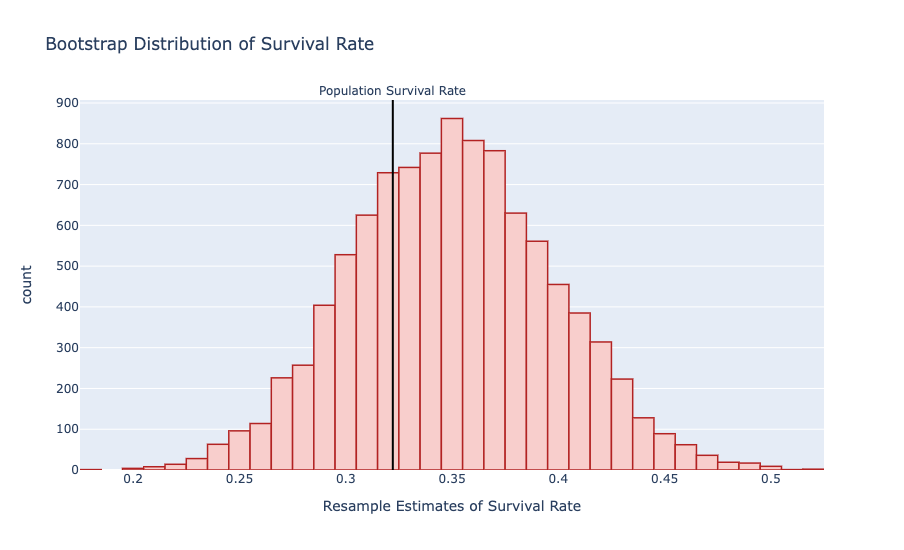

In [194]:
# Visualize the 10,000 sample estimates
resample_surv_rates = pd.Series(resample_surv_rates)
fig = px.histogram(resample_surv_rates,
                   title = "Bootstrap Distribution of Survival Rate",
                   labels = {"value":"Resample Estimates of Survival Rate"},
                   height = 550)

fig.update_traces(showlegend = False,
                  marker_color = "#F8CECC", 
                  marker_line_color = "firebrick",
                  marker_line_width = 1.5)

pop_surv_rate = titanic["survived"].value_counts(normalize = True).loc["yes"]
fig.add_vline(x = pop_surv_rate,
              line_width=2,            
              line_dash="solid",       
              line_color="black",         
              annotation_text="Population Survival Rate",      
              annotation_position="top")

Generally speaking, **we've constructed something very similar to the sampling distribution, but with just one sample!**

Contrast this with the sampling distribution histogram we constructed above and explore their similarities and differences

* The shape is similar
* The spread is similar
* The center is shifted slightly

In [189]:
print(f"St. Dev. of Sampling Distribution of Survival Rates:  {np.std(sample_surv_rates)}")
print(f"St. Dev. of Bootstrap Distribution of Survival Rates: {np.std(resample_surv_rates)}")

St. Dev. of Sampling Distribution of Survival Rates:  0.04549361607962154
St. Dev. of Bootstrap Distribution of Survival Rates: 0.04749241185705354


In [188]:
print(f"Mean of Sampling Distribution of Survival Rates:  {np.mean(sample_surv_rates)}")
print(f"Mean of Bootstrap Distribution of Survival Rates: {np.mean(resample_surv_rates)}")

Mean of Sampling Distribution of Survival Rates:  0.32183599999999996
Mean of Bootstrap Distribution of Survival Rates: 0.349896


**Questions:** 
* Why is the center shifted? 
* Does it matter?

---

### Bootstrap Sample Error

Recall, **sample error** is defined as $$\text{sample error} = a(\mathcal{S})-a(\mathcal{P}).$$

We can perform a similar calculation in this context noting that we're now treating $\mathcal{S}$ as if it were $ \mathcal{P}$ and likewise $\mathcal{S}^*$ as if it were $\mathcal{S}$.

We thus define **bootstrap sample error** as $$\text{bootstrap sample error} = a(\mathcal{S}^*)-a(\mathcal{S}).$$

Remember that in the confidence interval defined previously $$[\text{estimate}-e, \text{ estimate} + e],$$ the margin of error $e$ was a percentile of the absolute sample errors. 
* In practice we cannot know the true sample errors, but we can estimate them with bootstrap sample errors. 
* We can therefore also estimate the margin of error $e$ as a percentile of the absolute bootstrap sample errors. We will call the bootstrap margin of error $e^*$.

In the previous example we found $e$ as follows:

In [191]:
sample_errors = sample_surv_rates - pop_surv_rate
e = sample_errors.abs().quantile(0.95)
print(e)

0.0878432260987766


The analogous calculation using the bootstrap sample errors is as follows:

In [197]:
resample_errors = resample_surv_rates - S["survived"].value_counts(normalize = True).get("yes")
e_star = resample_errors.abs().quantile(0.95)
print(e_star)

0.09000000000000002


Despite the shift in the bootstrap distribution relative to the sampling distribution, there is good agreement between percentile of the true sample error distribution and bootstrap sample error distribution.

This gives a tool for constructing confidence intervals when you have just one sample.

---

### The Percentile Method Bootstrap Confidence Interval

We have seen that a confidence interval can be constructed as $$[\text{estimate}-e, \text{ estimate} + e],$$ but this required knowing $e$ which was impossible with only one sample. 

However, we've now seen we can estimate $e$ using the bootstrap, which suggests we should be able calculate the confidence interval as $$[\text{estimate}-e^*, \text{ estimate} + e^*],$$ where $e^*$ is a percentile of the absolute bootstrap sample errors.

In particular, for a C% confidence interval, $e^*$ should be the Cth percentile of the absolute bootstrap sample errors. This is called a **percentile method** bootstrap confidence interval.

Let's calculate this interval for the single sample we took at the beginning of this section.

In [201]:
estimate = S["survived"].value_counts(normalize = True).get("yes")
print(f"lower confidence limit: {estimate - e_star}")
print(f"upper confidence limit: {estimate + e_star}")

lower confidence limit: 0.25999999999999995
upper confidence limit: 0.44


**Questions:**

* How did we do? Did the confidence interval capture the true survival rate?

* How often should we expect such a confidence interval to contain the true population attribute value?

#### An Even Easier Calculation

It turns out that there is a more direct calculation (which does not require calculating the bootstrap sample errors) that gets us to the same answer. 

If $a(\mathcal{S}_1^*),a(\mathcal{S}_1^*),\ldots, a(\mathcal{S}_B^*)$ are your bootstrap estimates of the attribute of interest, the percentile method confidence interval is very simply defined by two specific percentiles of these values. In particular, for confidence level C%, the lower limit given by the (100-C)/2 percentile and upper limit is given by the (100+C)/2 percentile.

Observe:

In [212]:
C = 95
print(f"lower confidence limit: {np.percentile(resample_surv_rates, (100-C)/2)}")
print(f"upper confidence limit: {np.percentile(resample_surv_rates, (100+C)/2)}")

lower confidence limit: 0.26
upper confidence limit: 0.44


This is not a coincidence. These will always be in exact agreement.

---



### ACTIVITY 💻: Investigate the coverage of the percentile method confidence interval.


---